In [1]:
import sys
from pathlib import Path

ROOT = Path().resolve().parent

sys.path.insert(0, str(ROOT / "results" / "evaluation" ))

### *Functions*

#### Correlation

In [3]:
import numpy as np
import pandas as pd
from scipy.stats import kendalltau, pearsonr
import matplotlib.pyplot as plt
import seaborn as sns


def get_corr_matrix(df, method="pearson"):
    corr = df.drop(columns=["name"]).corr(method=method)
    return corr


def get_p_values(df, method="pearson"):
  df = df.select_dtypes(include=[np.number])
  cols = df.columns
  p_val_df = pd.DataFrame(np.zeros((len(cols), len(cols))), index=cols, columns=cols)

  for i in range(len(cols)):
    for j in range(len(cols)):
      if i == j:
        p_val_df.iloc[i, j] = 0.0
      else:
        if method == "pearson":
          _, p_val = pearsonr(df.iloc[:, i], df.iloc[:, j])
        elif method == "kendall":
          _, p_val = kendalltau(df.iloc[:, i], df.iloc[:, j])
        p_val_df.iloc[i, j] = p_val

  return p_val_df


def show_heatmap(corr, title):
    plt.figure(figsize=(8, 6))
    sns.heatmap(
        corr,
        annot=True,
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        fmt=".2f",
        linewidths=0.5,
    )
    
    plt.title(title)
    plt.show()


def show_scatterplot(df, x, y, title, xlabel = None, ylabel = None):
    xlabel = xlabel or x
    ylabel = ylabel or y

    sns.set_theme(style="whitegrid")
    
    plt.figure(figsize=(8, 6))
    sns.scatterplot(
        data=df,
        x=x,
        y=y,
        palette="deep",
        s=100,
    )
    
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.show()

#### Regression

In [4]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

def vif_table(df, predictors):
    sub = df[predictors].dropna()
    X = sm.add_constant(sub).values
    cols = ['const'] + predictors
    vifs = [variance_inflation_factor(X, i) for i in range(X.shape[1])]
    return pd.DataFrame({'variable': cols, 'VIF': vifs}).iloc[1:]


def run_ols(df, predictors, target):
    sub = df[predictors + [target]].dropna()
    X = sm.add_constant(sub[predictors])
    y = sub[target]
    model = sm.OLS(y, X).fit()
    return model, sub


def coef_table(model):
    ci = model.conf_int()
    return pd.DataFrame({
        "coef": model.params,
        "std_err": model.bse,
        "t": model.tvalues,
        "p": model.pvalues,
        "ci_low": ci[0],
        "ci_high": ci[1],
    }).rename_axis("variable").reset_index()


def fit_stats(model, tgt):
    return {
        "target": tgt,
        "n": int(model.nobs),
        "R2": model.rsquared,
        "adjR2": model.rsquared_adj,
        "F": model.fvalue,
        "F_p": model.f_pvalue,
        "AIC": model.aic,
        "BIC": model.bic,
    }


def run_regression(df, targets, predictors, out_dir):
    out_dir.mkdir(parents=True, exist_ok=True)
    all_coefs, all_stats = [], []
    for tgt in targets:
        model, sub = run_ols(df, predictors, tgt)
    
        coefs = coef_table(model)
    
        all_coefs.append(coefs.assign(target=tgt))
        all_stats.append(fit_stats(model, tgt))
    
        print(f"\n--- {tgt} ---")
        print(model.summary().tables[1])
        print(f"n={int(model.nobs)}  R2={model.rsquared:.3f}  "
          f"adj.R2={model.rsquared_adj:.3f}  F p={model.f_pvalue:.4f}")
    
    pd.concat(all_coefs, ignore_index=True).to_csv(out_dir / "ols_coef_all.csv", index=False)
    pd.DataFrame(all_stats).to_csv(out_dir / "ols_fit_stats.csv", index=False)

#### LOOCV

In [5]:
def loocv_metrics(df, predictors, target):
    model, sub = run_ols(df, predictors, target)
    loo_resid = model.get_influence().resid_press
    y = sub[target].to_numpy()

    press = float((loo_resid ** 2).sum())
    sst = float(((y - y.mean()) ** 2).sum())
    return {
        "target": target,
        "R2_in": model.rsquared,
        "adjR2_in": model.rsquared_adj,
        "Q2": 1 - press / sst,
        "RMSE": np.sqrt(press / len(y)),
    }


def loocv_summary(df, targets, predictors, out_dir):
    summary = pd.DataFrame([loocv_metrics(df, predictors, t) for t in targets]).set_index("target")
    out_dir.mkdir(parents=True, exist_ok=True)
    summary.to_csv(out_dir / "loocv_summary.csv")
    return summary.round(3)

### *Group 1*

In [10]:
columns = ["name", "complexity_avg_raw_std", "complexity_avg_norm_std", 
           "complexity_div_std", "complexity_disp_std",  "complexity_diss_aa_seq_std",
           "f_score_imtf", "f_score_imts", "f_score_imto", 
           "f_score_imftf", "f_score_imfts", "f_score_imfto"]

# real life data
path = ROOT / "results" / "evaluation" / "real_life"
rl_complexity_path = path / "complexity.csv"
rl_b_complexity_path = path / "baseline_complexity.csv"
rl_quality_path = path / "quality.csv"

rl_c_df = pd.read_csv(rl_complexity_path)
rl_bc_df = pd.read_csv(rl_b_complexity_path)
rl_q_df = pd.read_csv(rl_quality_path)

rl_df_merge_1 = pd.merge(rl_c_df, rl_q_df, on="name", how="inner")
rl_df_merge_2 = pd.merge(rl_df_merge_1, rl_bc_df, on="name", how="inner")
rl_df = rl_df_merge_2[columns]

# synthetic data
path = ROOT / "results" / "evaluation" / "synthetic"
sy_complexity_path = path / "complexity.csv"
sy_b_complexity_path = path / "baseline_complexity.csv"
sy_quality_path = path / "quality.csv"

sy_c_df = pd.read_csv(sy_complexity_path)
sy_bc_df = pd.read_csv(sy_b_complexity_path)
sy_q_df = pd.read_csv(sy_quality_path)

sy_df_merge_1 = pd.merge(sy_c_df, sy_q_df, on="name", how="inner")
sy_df = sy_df_merge[columns]

# complete dataset
rl_sy_df = pd.concat([rl_df, sy_df], axis=0, ignore_index=True)

print(rl_sy_df.shape)

(39, 12)


### *Group 2*

In [5]:
# simulated data
path = ROOT / "results" / "evaluation" / "simulated"
sm_complexity_path = path / "complexity.csv"
sm_quality_path = path / "quality.csv"

sm_c_df = pd.read_csv(sm_complexity_path)
sm_q_df = pd.read_csv(sm_quality_path)

sm_df_merge = pd.merge(sm_c_df, sm_q_df, on="name", how="inner")
sm_df = sm_df_merge[columns]

print(sm_df)

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\Jiayuan\\Research\\Translucent Log Complexity\\translucent-log-complexity\\results\\evaluation\\simulated\\quality.csv'

### *Analysis*

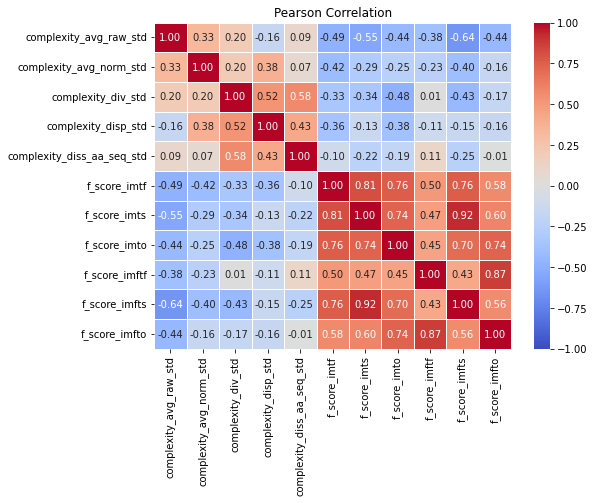

In [6]:
p_corr = get_corr_matrix(rl_sy_df)
show_heatmap(p_corr, "Pearson Correlation")

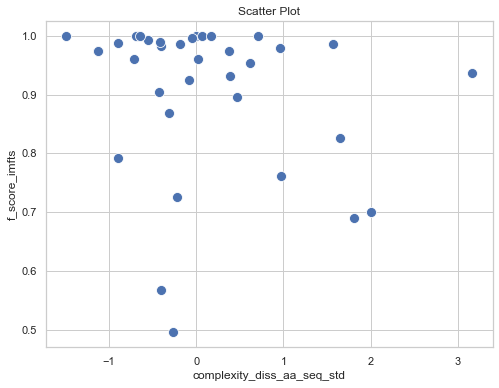

In [19]:
show_scatterplot(rl_sy_df, "complexity_diss_aa_seq_std", "f_score_imfts", title = "Scatter Plot")

In [17]:
path_1 = ROOT / "results" / "evaluation" / "group1_corr" / "p_corr.csv"
path_2 = ROOT / "results" / "evaluation" / "group1_corr" / "p_p_values.csv"

p_p_values = get_p_values(rl_sy_df)
p_corr.to_csv(path_1, index=False)
p_p_values.to_csv(path_2, index=False)

In [18]:
path_3 = ROOT / "results" / "evaluation" / "group1_corr" / "k_corr.csv"
path_4 = ROOT / "results" / "evaluation" / "group1_corr" / "k_p_values.csv"

k_corr = get_corr_matrix(rl_sy_df, "kendall")
k_p_values = get_p_values(rl_sy_df, "kendall")
k_corr.to_csv(path_3, index=False)
k_p_values.to_csv(path_4, index=False)

In [7]:
predictors = ["complexity_avg_raw_std", "complexity_avg_norm_std", 
              "complexity_div_std", "complexity_disp_std",  "complexity_diss_aa_seq_std"]

print(vif_table(rl_sy_df, predictors))

                     variable       VIF
1      complexity_avg_raw_std  1.483509
2     complexity_avg_norm_std  1.511474
3          complexity_div_std  1.927070
4         complexity_disp_std  2.080104
5  complexity_diss_aa_seq_std  1.585343


In [11]:
predictors = [
    # Complexity.perform_measurements
    "magnitude",
    "support",
    "variety",
    "level_of_detail",
    "time_granularity",
    "structure",
    "affinity",
    "trace_length_min",
    "trace_length_avg",
    "trace_length_max",
    "distinct_traces",
    "deviation_from_random",
    "lempel_ziv_complexity",
    "pentland_task_complexity",
    "pentland_process_complexity",
    # Complexity.graph_complexity
    "variant_entropy",
    "variant_entropy_norm",
    # Complexity.log_complexity
    "sequence_entropy",
    "sequence_entropy_norm",
    "sequence_entropy_linear",
    "sequence_entropy_linear_norm",
    "sequence_entropy_exp",
    "sequence_entropy_exp_norm",
]

print(vif_table(rl_df_merge_2, predictors))

                        variable  VIF
1                      magnitude  inf
2                        support  inf
3                        variety  inf
4                level_of_detail  inf
5               time_granularity  inf
6                      structure  inf
7                       affinity  inf
8               trace_length_min  inf
9               trace_length_avg  inf
10              trace_length_max  inf
11               distinct_traces  inf
12         deviation_from_random  inf
13         lempel_ziv_complexity  inf
14      pentland_task_complexity  inf
15   pentland_process_complexity  inf
16               variant_entropy  inf
17          variant_entropy_norm  inf
18              sequence_entropy  inf
19         sequence_entropy_norm  inf
20       sequence_entropy_linear  inf
21  sequence_entropy_linear_norm  inf
22          sequence_entropy_exp  inf
23     sequence_entropy_exp_norm  inf


C:\Users\jiayuan.chen\Documents\translucent-log-complexity\venv\lib\site-packages\statsmodels\regression\linear_model.py:1781: RuntimeWarning: divide by zero encountered in double_scalars
  return 1 - self.ssr/self.centered_tss
C:\Users\jiayuan.chen\Documents\translucent-log-complexity\venv\lib\site-packages\statsmodels\stats\outliers_influence.py:198: RuntimeWarning: divide by zero encountered in double_scalars
  vif = 1. / (1. - r_squared_i)


In [12]:
print(rl_df_merge_2[predictors])

    magnitude  support  variety  level_of_detail  time_granularity  structure  \
0       57782     5201       10         4.759469      0.000000e+00   0.740000   
1         140       14        4         4.000000      0.000000e+00   0.562500   
2       18332     1776        3         1.000000      0.000000e+00   0.666667   
3        3056      711        3         2.347398      1.113085e+06   0.444444   
4           8        2        3         1.500000      3.239910e+05   0.555556   
5         188       32        3         3.000000      2.553188e+03   0.333333   
6       94677    20759        8         4.560769      1.161256e+00   0.812500   
7         484       70        5         5.000000      9.412029e+04   0.680000   
8       16121     6586       12         2.306711      6.215825e+05   0.812500   
9       18954     3595        7         5.272323      3.581231e+00   0.877551   
10      10774     1013       12        10.635735      2.837019e+01   0.909722   
11       9791      913      